In [7]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

recurrent_radius = 2  


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler',name='P_E')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler',name='P_I')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=input_freq * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.1 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.42, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.8#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.32, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

   
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_est_mon = StateMonitor(P_E, variables=['r_est'], record=[45], name = 'r_est',dt=record_dt)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



# def show_rand_rate(net, show_time = 1000*ms):
#     N_inp=net['inp'].N
#     rates = np.random.normal(loc=40, scale=0, size=N_inp)
#     rate_img = np.clip(rates, 5, 50)*Hz
#     net['inp'].rates = rate_img
#     net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA,input_freq=input_freq)
    net.run(show_time, report = 'text')
    # show_rand_rate(net,show_time=show_time)
    return net



In [8]:
start_scope()
seed(1234)
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=2000*second)

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 2. ks
164.623 s (8%) simulated in 10s, estimated 1m 51s remaining.
0.33782 ks (16%) simulated in 20s, estimated 1m 38s remaining.
0.507451 ks (25%) simulated in 30s, estimated 1m 28s remaining.
0.677759 ks (33%) simulated in 40s, estimated 1m 18s remaining.
0.852757 ks (42%) simulated in 50s, estimated 1m 7s remaining.
1.025487 ks (51%) simulated in 1m 0s, estimated 57s remaining.
1.196415 ks (59%) simulated in 1m 10s, estimated 47s remaining.
1.37478 ks (68%) simulated in 1m 20s, estimated 36s remaining.
1.551954 ks (77%) simulated in 1m 30s, estimated 26s remaining.
1.721666 ks (86%) simulated in 1m 40s, estimated 16s remaining.
1.895993 ks (94%) simulated in 1m 50s, estimated 6s remaining.
2. ks (100%) simulated in 1m 55s


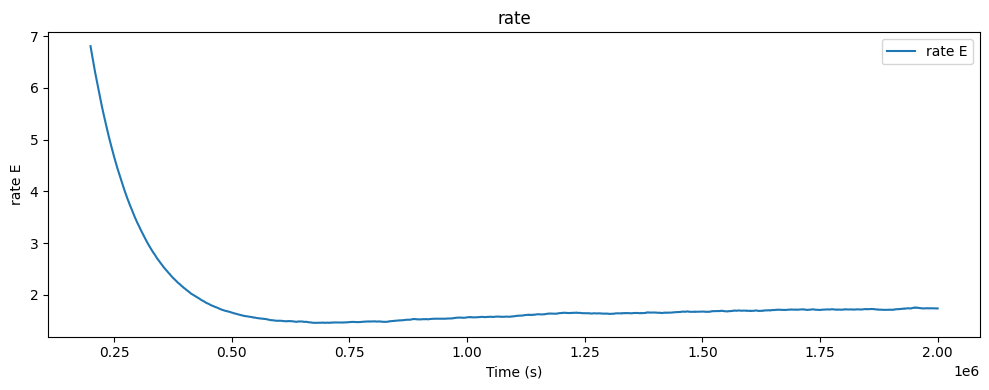

In [9]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[1000:]/ms, r_est_E.r_pop_E[0,1000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

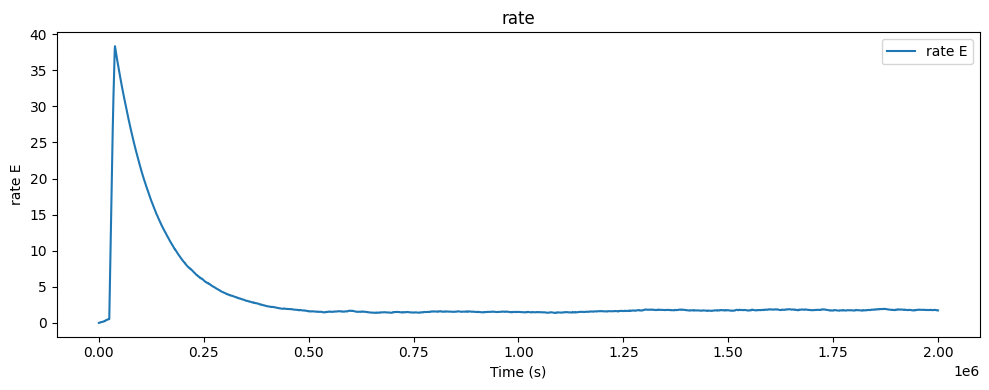

In [10]:
r_est_E = net['r_est']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t/ms, r_est_E.r_est[0]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

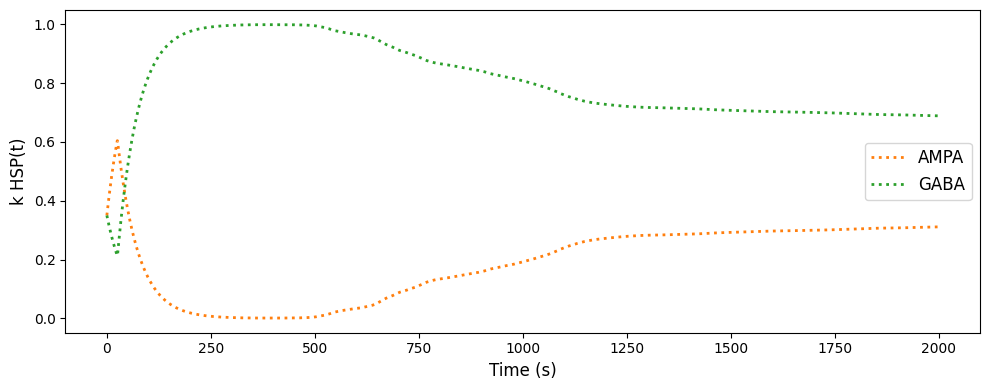

In [11]:
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/second, kAMPA_mon_E.k_AMPA_E_hsp[45], label='AMPA',color='tab:orange',linestyle=':',linewidth=2)
plt.plot(kGABA_mon_E.t/second, kGABA_mon_E.k_GABA_E_hsp[45], label='GABA',color='tab:green',linestyle=':',linewidth=2)
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('k HSP(t)',fontsize=12)
#plt.title('Homeostatic Synaptic Scaling')
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

In [12]:
net.store('baseline')

In [17]:
def run_full_hsp_trajectory(net, alpha=1.0, run_time=2000*second,
                            analysis_start_s=2000.0,input_freq=40*Hz,
                            tau_ins_AMPA=100*second,
                            tau_int_AMPA=50*second,
                            tau_ins_GABA=100*second,
                            tau_int_GABA=50*second,
                            neuron_idx=45):

    net.restore('baseline')
    inp = net['inp']
    inp.rates=input_freq
    P_E = net['P_E']
    PG_E = net['PG_E']

    gAMPA_mon_E = net['k_AMPA_E_hsp']
    gGABA_mon_E = net['k_GABA_E_hsp']
    r_est_mon = net['r_est']   # StateMonitor on neuron 45 in your build_network

    baseline_w = float(PG_E.w[0])
    PG_E.w[:] = alpha * baseline_w

    P_E.tau_ins_AMPA_E = tau_ins_AMPA
    P_E.tau_int_AMPA_E = tau_int_AMPA
    P_E.tau_ins_GABA_E = tau_ins_GABA
    P_E.tau_int_GABA_E = tau_int_GABA

    net.run(run_time, report='text')

    # Use the SAME monitor timebase as r_est_mon
    t_all = np.array(r_est_mon.t / second)
    mask = t_all >= analysis_start_s

    return {
        't': t_all[mask],
        'r_est_trace': np.array(r_est_mon.r_est[0, mask] / Hz),   # neuron 45
        'kE_trace': np.array(gAMPA_mon_E.k_AMPA_E_hsp[neuron_idx, mask]),
        'kI_trace': np.array(gGABA_mon_E.k_GABA_E_hsp[neuron_idx, mask]),
    }

In [18]:
seed(1234)
res_trace = run_full_hsp_trajectory(
    net,
    alpha=1,
    run_time=2000*second,
    input_freq=40*Hz,
    analysis_start_s=2000.0,
    tau_ins_AMPA=100.0*second,
    tau_int_AMPA=50.0*second,
    tau_ins_GABA=100.0*second,
    tau_int_GABA=50.0*second,
    neuron_idx=45
)

t = res_trace['t']
r_est_trace = res_trace['r_est_trace']
kE_trace = res_trace['kE_trace']
kI_trace = res_trace['kI_trace']

Starting simulation at t=2. ks for a duration of 2. ks
100.744 s (5%) simulated in 10s, estimated 3m 9s remaining.
196.981 s (9%) simulated in 20s, estimated 3m 3s remaining.
285.236 s (14%) simulated in 30s, estimated 3m 0s remaining.
0.375683 ks (18%) simulated in 40s, estimated 2m 53s remaining.
0.456805 ks (22%) simulated in 50s, estimated 2m 49s remaining.
0.543242 ks (27%) simulated in 1m 0s, estimated 2m 41s remaining.
0.634545 ks (31%) simulated in 1m 10s, estimated 2m 31s remaining.
0.71427 ks (35%) simulated in 1m 20s, estimated 2m 24s remaining.
0.795711 ks (39%) simulated in 1m 30s, estimated 2m 16s remaining.
0.876704 ks (43%) simulated in 1m 40s, estimated 2m 8s remaining.
0.965985 ks (48%) simulated in 1m 50s, estimated 1m 58s remaining.
1.050952 ks (52%) simulated in 2m 0s, estimated 1m 48s remaining.
1.137237 ks (56%) simulated in 2m 10s, estimated 1m 39s remaining.
1.225873 ks (61%) simulated in 2m 20s, estimated 1m 28s remaining.
1.313316 ks (65%) simulated in 2m 30s

In [19]:
from scipy.signal import welch
import numpy as np
import matplotlib.pyplot as plt
from brian2 import *

def compute_r_est_spectrum(t, r, fmax=0.2):
    """
    t in seconds, r in Hz.
    Returns frequencies and power spectrum.
    """
    dt = np.median(np.diff(t))
    fs = 1.0 / dt

    r = np.asarray(r)
    r = r - np.mean(r)   # remove DC/steady component

    freqs, power = welch(
        r,
        fs=fs,
        nperseg=min(2048, len(r)),
        noverlap=None,
        detrend='constant'
    )

    keep = freqs <= fmax
    return freqs[keep], power[keep]


def run_input_frequency_sweep_regular(
    net,
    input_freqs_hz,
    run_time=3000*second,
    analysis_start_s=2000.0,
    alpha=1.0,
    neuron_idx=45,
    fmax=0.2
):
    spectra = []
    freqs_ref = None
    mean_r_est = []

    for f_in in input_freqs_hz:
        print(f"\nRunning input frequency = {f_in:.2f} Hz")

        res = run_full_hsp_trajectory(
            net,
            alpha=alpha,
            run_time=run_time,
            input_freq=f_in*Hz,
            analysis_start_s=analysis_start_s,
            tau_ins_AMPA=100.0*second,
            tau_int_AMPA=50.0*second,
            tau_ins_GABA=100.0*second,
            tau_int_GABA=50.0*second,
            neuron_idx=neuron_idx
        )

        
        t = res["t"]
        mask = t >= analysis_start_s
        t=t[mask]
        r = res["r_est_trace"]
        r=r[mask]

        if len(t) < 20:
            raise ValueError(
                f"Trace too short for input {f_in} Hz. "
                "Decrease analysis_start_s or increase run_time."
            )

        freqs, power = compute_r_est_spectrum(t, r, fmax=fmax)

        if freqs_ref is None:
            freqs_ref = freqs
        else:
            power = np.interp(freqs_ref, freqs, power)

        spectra.append(power)
        mean_r_est.append(np.mean(r))

    spectra = np.array(spectra).T
    mean_r_est = np.array(mean_r_est)

    return {
        "input_freqs_hz": np.array(input_freqs_hz),
        "spectral_freqs_hz": freqs_ref,
        "power": spectra,
        "mean_r_est": mean_r_est
    }

In [ ]:
seed(1234)

input_freqs_hz = np.linspace(25, 45, 41)

sweep_regular = run_input_frequency_sweep_regular(
    net,
    input_freqs_hz=input_freqs_hz,
    run_time=5000*second,
    analysis_start_s=2000.0,
    alpha=1.0,
    neuron_idx=45,
    fmax=0.1
)


Running input frequency = 30.00 Hz
Starting simulation at t=2. ks for a duration of 4. ks
84.237 s (2%) simulated in 10s, estimated 7m 45s remaining.
181.862 s (4%) simulated in 20s, estimated 7m 0s remaining.
279.52 s (6%) simulated in 30s, estimated 6m 39s remaining.
0.361802 ks (9%) simulated in 40s, estimated 6m 42s remaining.
0.444338 ks (11%) simulated in 50s, estimated 6m 40s remaining.
0.524485 ks (13%) simulated in 1m 0s, estimated 6m 40s remaining.
0.606027 ks (15%) simulated in 1m 10s, estimated 6m 34s remaining.
0.689454 ks (17%) simulated in 1m 20s, estimated 6m 26s remaining.
0.775619 ks (19%) simulated in 1m 30s, estimated 6m 16s remaining.
0.853789 ks (21%) simulated in 1m 40s, estimated 6m 10s remaining.
0.939709 ks (23%) simulated in 1m 50s, estimated 6m 0s remaining.
1.031835 ks (25%) simulated in 2m 0s, estimated 5m 46s remaining.
1.119072 ks (27%) simulated in 2m 10s, estimated 5m 36s remaining.
1.206856 ks (30%) simulated in 2m 20s, estimated 5m 25s remaining.
1.

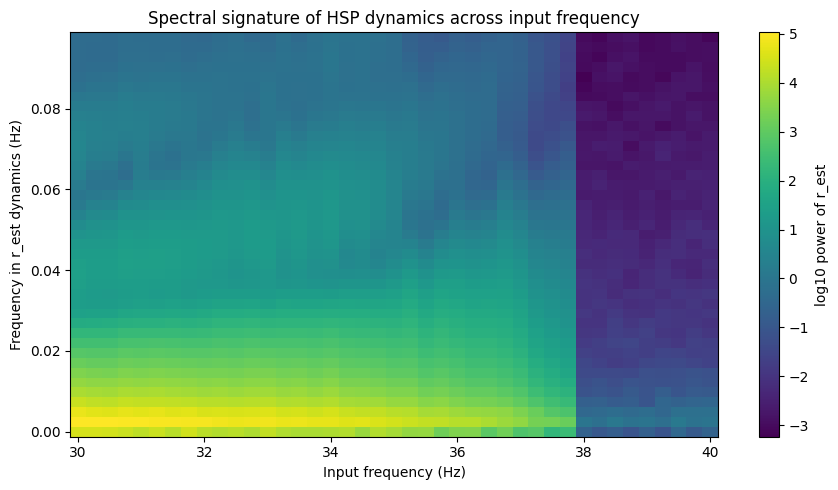

In [29]:
X = sweep_regular["input_freqs_hz"]
Y = sweep_regular["spectral_freqs_hz"]
P = sweep_regular["power"]

plt.figure(figsize=(9, 5))

plt.pcolormesh(
    X,
    Y,
    np.log10(P + 1e-12),
    shading="auto"
)

plt.colorbar(label="log10 power of r_est")
plt.xlabel("Input frequency (Hz)")
plt.ylabel("Frequency in r_est dynamics (Hz)")
plt.title("Spectral signature of HSP dynamics across input frequency")
plt.tight_layout()
plt.show()

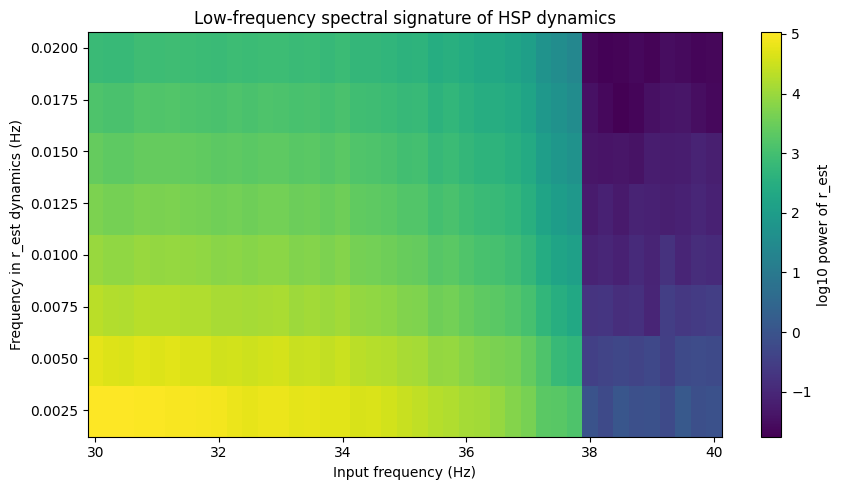

In [30]:
plt.figure(figsize=(9, 5))

P = sweep_regular["power"].copy()
Y = sweep_regular["spectral_freqs_hz"]
X = sweep_regular["input_freqs_hz"]

# remove DC component
P[Y == 0, :] = np.nan

keep = (Y > 0) & (Y <= 0.02)

plt.pcolormesh(
    X,
    Y[keep],
    np.log10(P[keep, :] + 1e-12),
    shading="auto"
)

plt.colorbar(label="log10 power of r_est")
plt.xlabel("Input frequency (Hz)")
plt.ylabel("Frequency in r_est dynamics (Hz)")
plt.title("Low-frequency spectral signature of HSP dynamics")
plt.tight_layout()
plt.show()

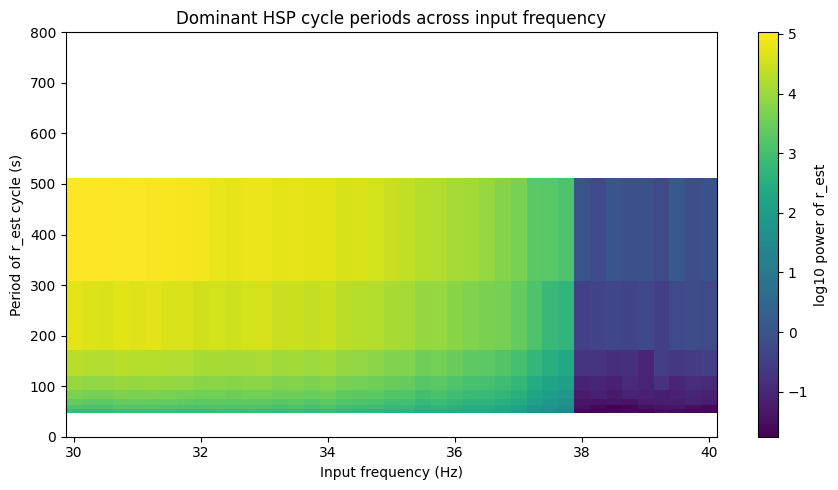

In [31]:
keep = (Y > 0) & (Y <= 0.02)

plt.figure(figsize=(9, 5))
plt.pcolormesh(
    X,
    1 / Y[keep],
    np.log10(P[keep, :] + 1e-12),
    shading="auto"
)

plt.colorbar(label="log10 power of r_est")
plt.xlabel("Input frequency (Hz)")
plt.ylabel("Period of r_est cycle (s)")
plt.ylim(0, 800)
plt.title("Dominant HSP cycle periods across input frequency")
plt.tight_layout()
plt.show()

In [32]:
def dominant_cycle_frequency(freqs, power, fmin=1/1000, fmax=0.02):
    keep = (freqs >= fmin) & (freqs <= fmax)

    dom_freqs = []
    dom_periods = []
    dom_power = []

    for j in range(power.shape[1]):
        p = power[keep, j]
        f = freqs[keep]

        idx = np.argmax(p)
        dom_freqs.append(f[idx])
        dom_periods.append(1 / f[idx])
        dom_power.append(p[idx])

    return np.array(dom_freqs), np.array(dom_periods), np.array(dom_power)

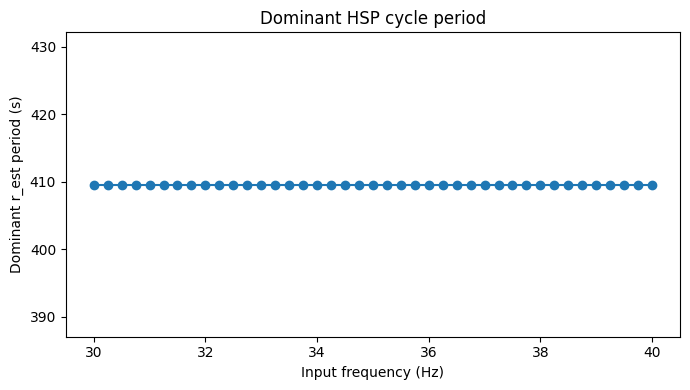

In [33]:
dom_f, dom_T, dom_P = dominant_cycle_frequency(Y, P)

plt.figure(figsize=(7, 4))
plt.plot(X, dom_T, marker="o")
plt.xlabel("Input frequency (Hz)")
plt.ylabel("Dominant r_est period (s)")
plt.title("Dominant HSP cycle period")
plt.tight_layout()
plt.show()